# Package importing

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import plotly.express as px

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
from xgboost import XGBRegressor
import joblib

In [2]:
df= pd.read_csv("survey_results_public.csv")

In [3]:
df.shape

(73268, 79)

In [4]:
df.columns

Index(['ResponseId', 'MainBranch', 'Employment', 'RemoteWork',
       'CodingActivities', 'EdLevel', 'LearnCode', 'LearnCodeOnline',
       'LearnCodeCoursesCert', 'YearsCode', 'YearsCodePro', 'DevType',
       'OrgSize', 'PurchaseInfluence', 'BuyNewTool', 'Country', 'Currency',
       'CompTotal', 'CompFreq', 'LanguageHaveWorkedWith',
       'LanguageWantToWorkWith', 'DatabaseHaveWorkedWith',
       'DatabaseWantToWorkWith', 'PlatformHaveWorkedWith',
       'PlatformWantToWorkWith', 'WebframeHaveWorkedWith',
       'WebframeWantToWorkWith', 'MiscTechHaveWorkedWith',
       'MiscTechWantToWorkWith', 'ToolsTechHaveWorkedWith',
       'ToolsTechWantToWorkWith', 'NEWCollabToolsHaveWorkedWith',
       'NEWCollabToolsWantToWorkWith', 'OpSysProfessional use',
       'OpSysPersonal use', 'VersionControlSystem', 'VCInteraction',
       'VCHostingPersonal use', 'VCHostingProfessional use',
       'OfficeStackAsyncHaveWorkedWith', 'OfficeStackAsyncWantToWorkWith',
       'OfficeStackSyncHaveWork

In [5]:
df.head()

,ResponseId,MainBranch,Employment,RemoteWork,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,LearnCodeCoursesCert,YearsCode,...,TimeSearching,TimeAnswering,Onboarding,ProfessionalTech,TrueFalse_1,TrueFalse_2,TrueFalse_3,SurveyLength,SurveyEase,ConvertedCompYearly
0,1,None of these,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,I am a developer by profession,"Employed, full-time",Fully remote,Hobby;Contribute to open-source projects,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Too long,Difficult,NaN
2,3,"I am not primarily a developer, but I write co...","Employed, full-time","Hybrid (some remote, some in-person)",Hobby,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Books / Physical media;Friend or family member...,Technical documentation;Blogs;Programming Game...,NaN,14,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Neither easy nor difficult,40205.0
3,4,I am a developer by profession,"Employed, full-time",Fully remote,I don’t code outside of work,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)","Books / Physical media;School (i.e., Universit...",NaN,NaN,20,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Easy,215232.0
4,5,I am a developer by profession,"Employed, full-time","Hybrid (some remote, some in-person)",Hobby,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)","Other online resources (e.g., videos, blogs, f...",Technical documentation;Blogs;Stack Overflow;O...,NaN,8,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Too long,Easy,NaN


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 73268 entries, 0 to 73267
Data columns (total 79 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   ResponseId                      73268 non-null  int64  
 1   MainBranch                      73268 non-null  object 
 2   Employment                      71709 non-null  object 
 3   RemoteWork                      58958 non-null  object 
 4   CodingActivities                58899 non-null  object 
 5   EdLevel                         71571 non-null  object 
 6   LearnCode                       71580 non-null  object 
 7   LearnCodeOnline                 50685 non-null  object 
 8   LearnCodeCoursesCert            29389 non-null  object 
 9   YearsCode                       71331 non-null  object 
 10  YearsCodePro                    51833 non-null  object 
 11  DevType                         61302 non-null  object 
 12  OrgSize                         

# Visualization

In [7]:
def plot_line_chart(df, column, line=""):
    if line == '':
        line = df[column].value_counts().keys()[0:20]
    data = df[column].value_counts()[0:20]
    fig=px.line(x=line,y=data)
    fig.show()
    
def plot_bar_chart(df, column, line=""):
    if line == '':
        line = df[column].value_counts().keys()[0:20]
    data = df[column].value_counts()[0:20]
    fig=px.bar(x=line,y=data)
    fig.show()
    
def plot_pie_chart(df, column, line = ''):
    if line == '':
        line = df[column].value_counts().keys()[0:20]
    data = df[column].value_counts()[0:20]
    fig=px.pie(names=line,values=data)
    fig.show()

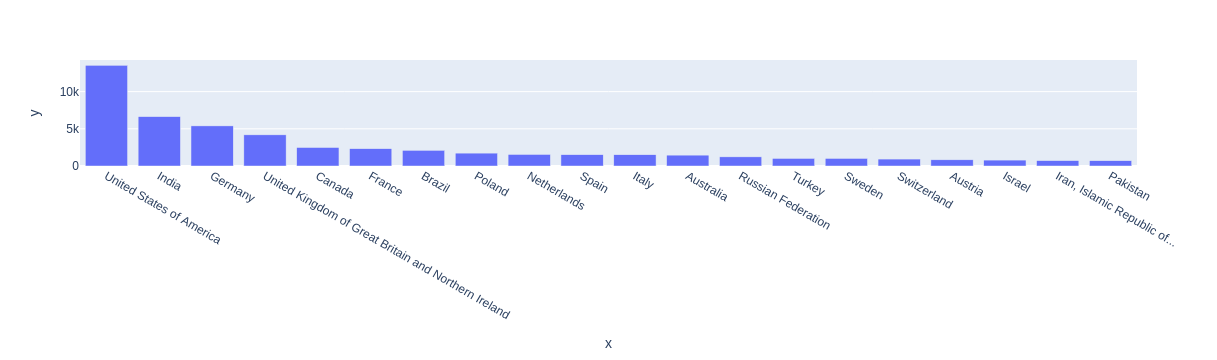

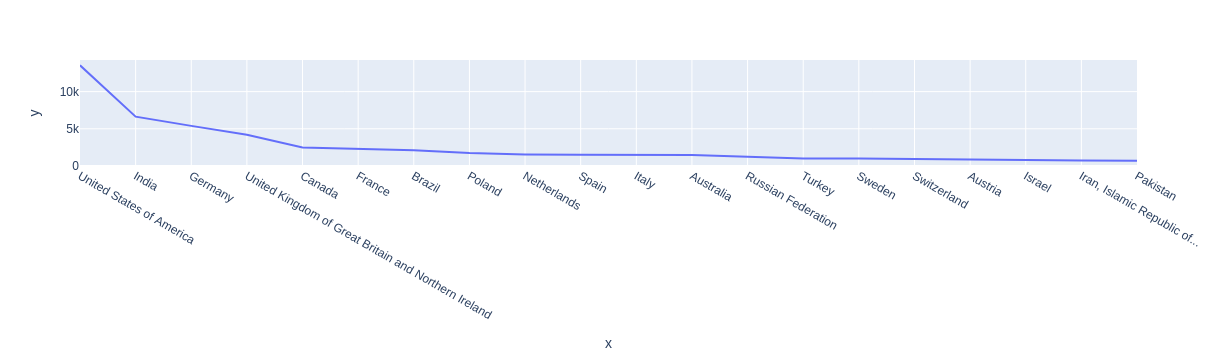

In [8]:
plot_bar_chart(df,"Country")
plot_line_chart(df,"Country")

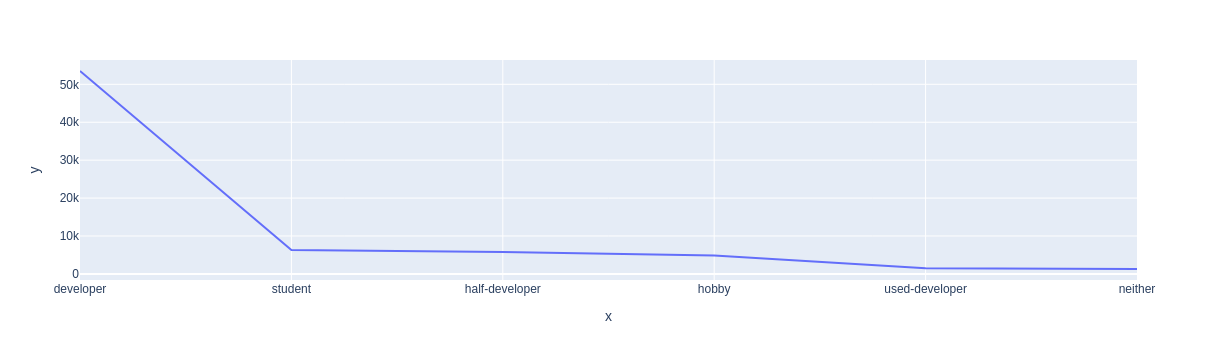

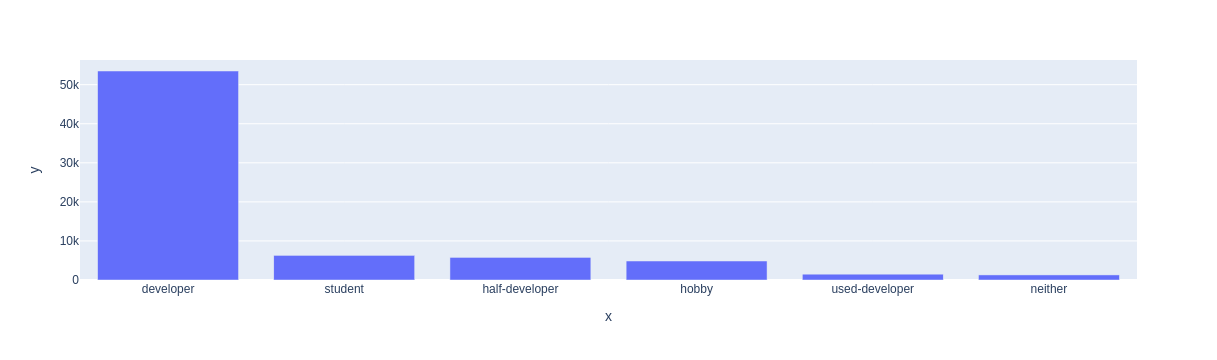

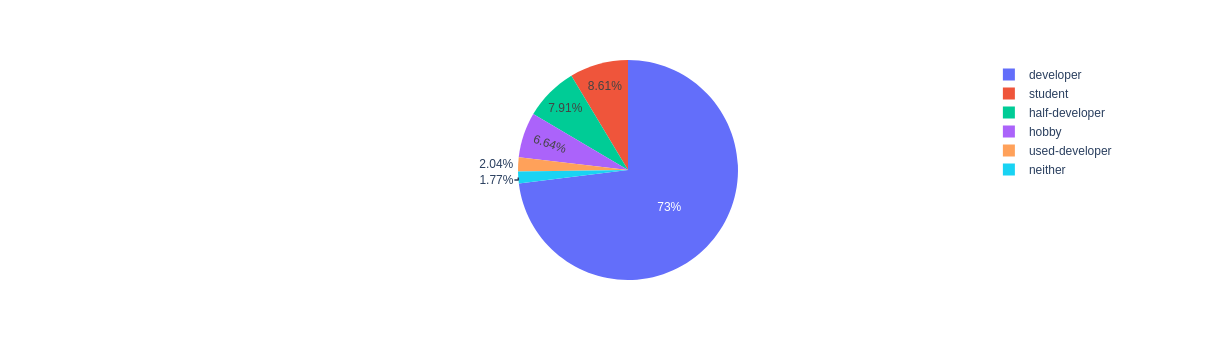

In [9]:
line = ['developer', 'student', 'half-developer', 'hobby', 'used-developer', 'neither']
plot_line_chart(df, 'MainBranch', line)
plot_bar_chart(df, 'MainBranch', line)
plot_pie_chart(df, 'MainBranch', line)

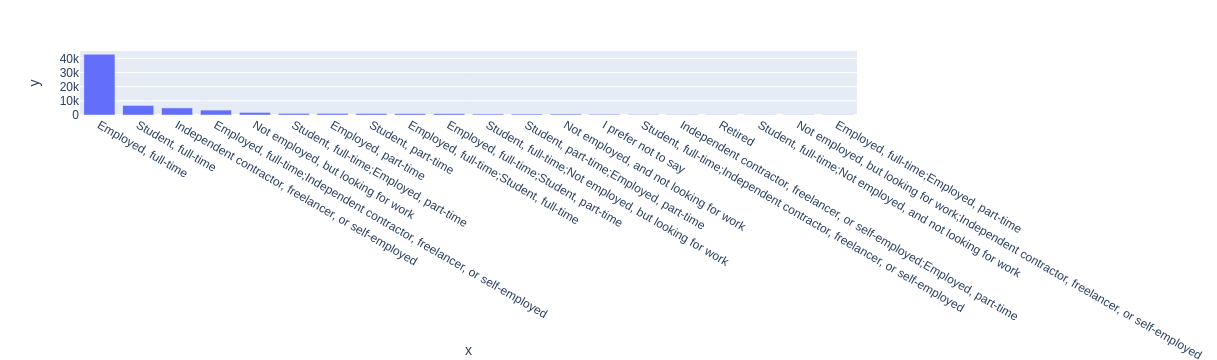

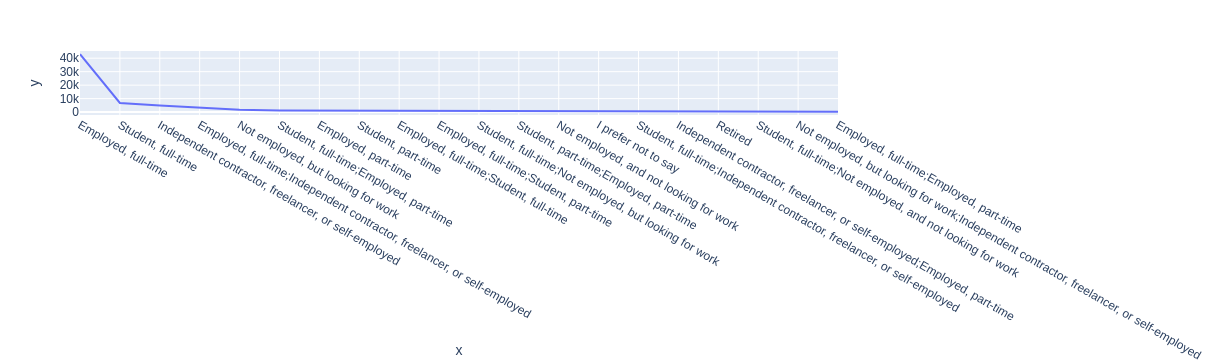

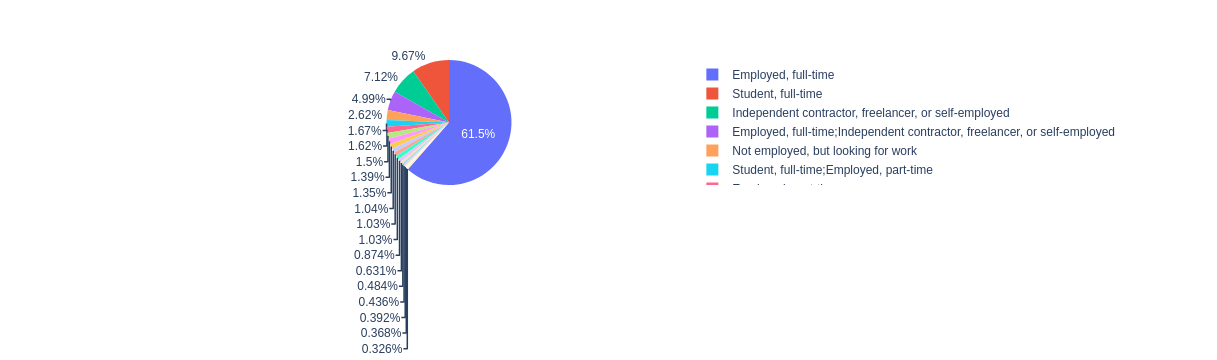

In [10]:
plot_bar_chart(df,"Employment")
plot_line_chart(df,"Employment")
plot_pie_chart(df,"Employment")

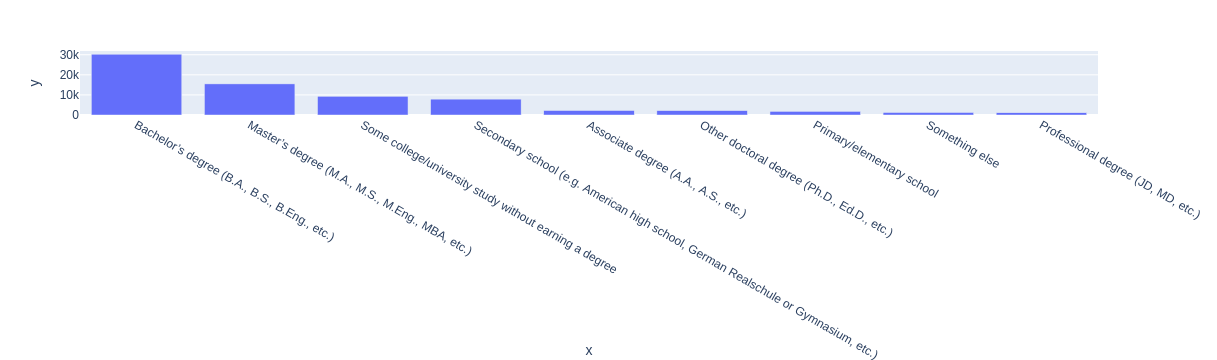

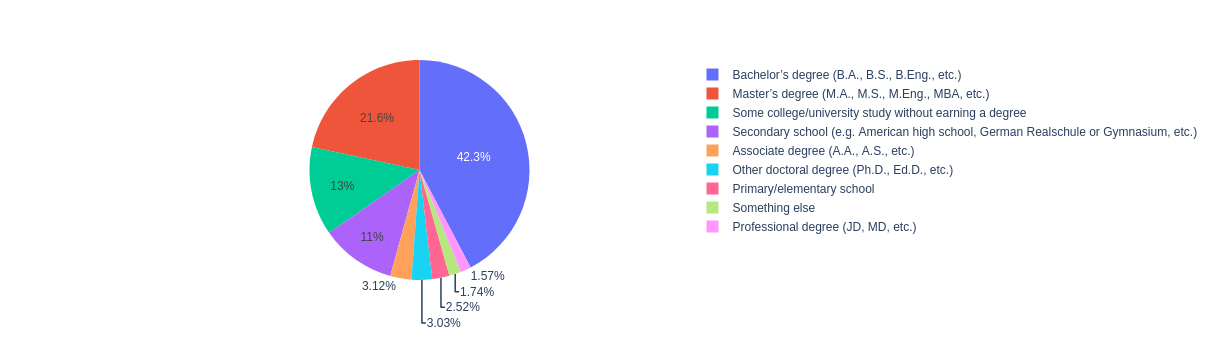

In [11]:
plot_bar_chart(df,"EdLevel")
plot_pie_chart(df,"EdLevel")

In [12]:
df.columns

Index(['ResponseId', 'MainBranch', 'Employment', 'RemoteWork',
       'CodingActivities', 'EdLevel', 'LearnCode', 'LearnCodeOnline',
       'LearnCodeCoursesCert', 'YearsCode', 'YearsCodePro', 'DevType',
       'OrgSize', 'PurchaseInfluence', 'BuyNewTool', 'Country', 'Currency',
       'CompTotal', 'CompFreq', 'LanguageHaveWorkedWith',
       'LanguageWantToWorkWith', 'DatabaseHaveWorkedWith',
       'DatabaseWantToWorkWith', 'PlatformHaveWorkedWith',
       'PlatformWantToWorkWith', 'WebframeHaveWorkedWith',
       'WebframeWantToWorkWith', 'MiscTechHaveWorkedWith',
       'MiscTechWantToWorkWith', 'ToolsTechHaveWorkedWith',
       'ToolsTechWantToWorkWith', 'NEWCollabToolsHaveWorkedWith',
       'NEWCollabToolsWantToWorkWith', 'OpSysProfessional use',
       'OpSysPersonal use', 'VersionControlSystem', 'VCInteraction',
       'VCHostingPersonal use', 'VCHostingProfessional use',
       'OfficeStackAsyncHaveWorkedWith', 'OfficeStackAsyncWantToWorkWith',
       'OfficeStackSyncHaveWork

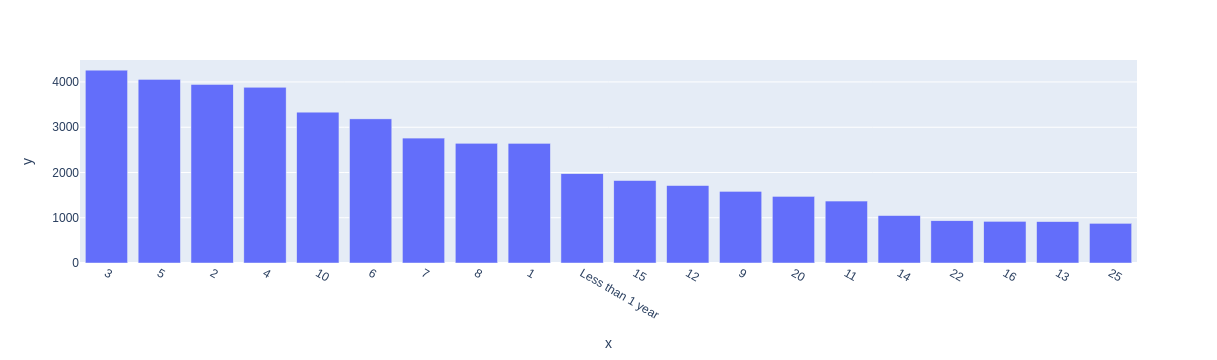

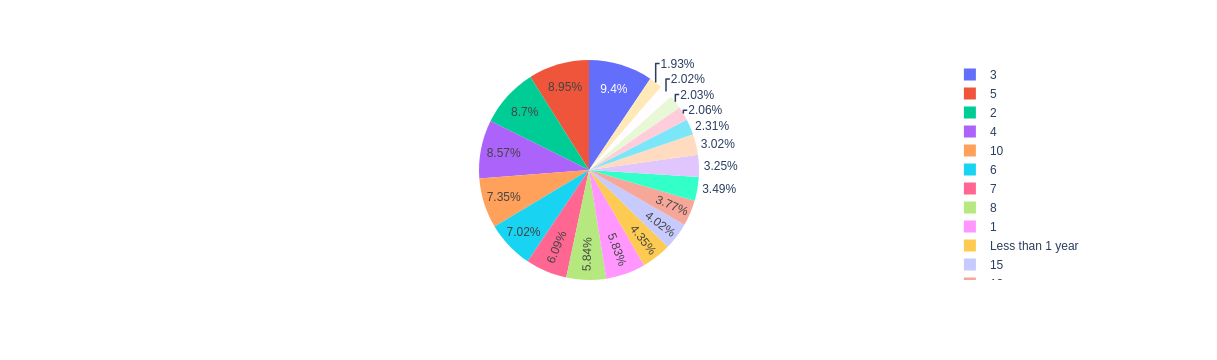

In [13]:
plot_bar_chart(df,"YearsCodePro")
plot_pie_chart(df,"YearsCodePro")

In [14]:
df[["DevType"]]

,DevType
0,NaN
1,NaN
2,Data scientist or machine learning specialist;...
3,"Developer, full-stack"
4,"Developer, front-end;Developer, full-stack;Dev..."
...,...
73263,"Developer, back-end"
73264,Data scientist or machine learning specialist
73265,"Developer, full-stack;Developer, desktop or en..."
73266,"Developer, front-end;Developer, desktop or ent..."


In [15]:
df_DevType = pd.DataFrame()
num = 0
str_list = []
for i in df['DevType']:
    num = num + 1
    if pd.isnull(i):
        continue
    data = i.split(";")
    for j in data:
        str_list.append(j)
df_DevType = pd.DataFrame(str_list, columns=['DevType'])
df_DevType.value_counts()

DevType                                      
Developer, full-stack                            28701
Developer, back-end                              26595
Developer, front-end                             15915
Developer, desktop or enterprise applications     9546
Developer, mobile                                 7634
DevOps specialist                                 6170
Student                                           5595
Cloud infrastructure engineer                     5283
Database administrator                            4934
System administrator                              4908
Developer, embedded applications or devices       3923
Project manager                                   3897
Designer                                          3764
Engineer, data                                    3600
Engineering manager                               3574
Data scientist or machine learning specialist     3424
Data or business analyst                          3201
Developer, QA or te

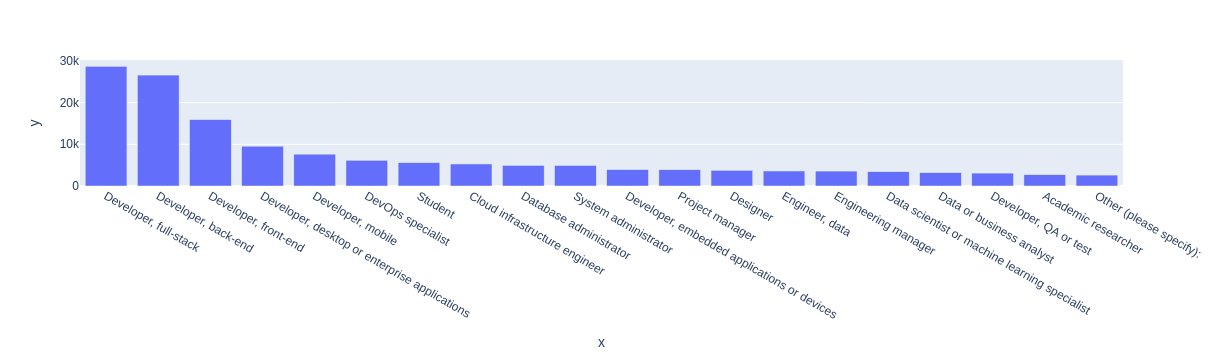

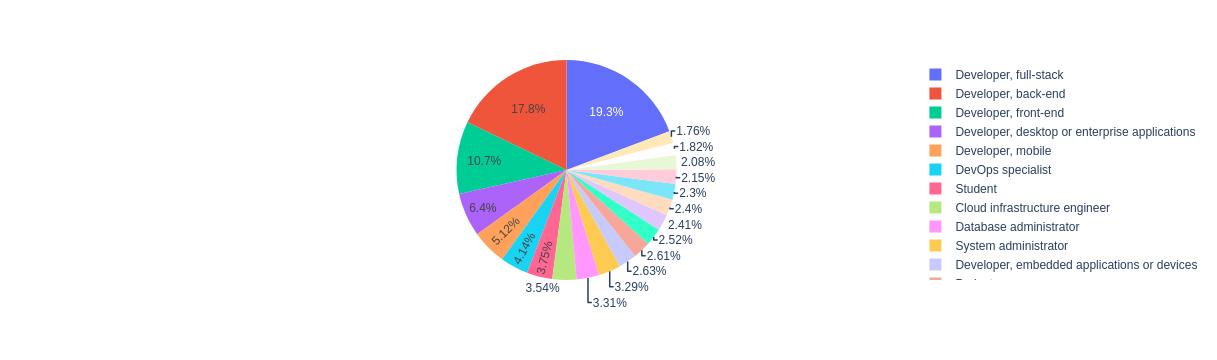

In [16]:
plot_bar_chart(df_DevType,"DevType")
plot_pie_chart(df_DevType,"DevType")

## Feature Selection

In [17]:
df = df[["Country", "EdLevel", "YearsCodePro","Employment", "ConvertedCompYearly"]]
df = df.rename({"ConvertedCompYearly": "Salary"}, axis=1)
df.sample()

,Country,EdLevel,YearsCodePro,Employment,Salary
36091,Turkey,"Secondary school (e.g. American high school, G...",NaN,"Student, part-time",NaN


In [18]:
df = df[df["Salary"].notnull()]
df.sample(5)

,Country,EdLevel,YearsCodePro,Employment,Salary
47644,Australia,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",10,"Employed, full-time",60155.0
10696,Germany,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",2,"Employed, full-time",46068.0
63887,United Kingdom of Great Britain and Northern I...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",2,"Employed, full-time",67782.0
15714,Canada,"Associate degree (A.A., A.S., etc.)",4,"Employed, full-time",140551.0
7321,Poland,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",4,"Employed, full-time",36072.0


In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 38071 entries, 2 to 73121
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Country       38071 non-null  object 
 1   EdLevel       38054 non-null  object 
 2   YearsCodePro  37935 non-null  object 
 3   Employment    38067 non-null  object 
 4   Salary        38071 non-null  float64
dtypes: float64(1), object(4)
memory usage: 1.7+ MB


In [20]:
df = df.dropna()
df.isnull().sum()

Country         0
EdLevel         0
YearsCodePro    0
Employment      0
Salary          0
dtype: int64

In [21]:
df.columns

Index(['Country', 'EdLevel', 'YearsCodePro', 'Employment', 'Salary'], dtype='object')

In [22]:
df["Country"].value_counts()

Country
United States of America                                8684
Germany                                                 2901
United Kingdom of Great Britain and Northern Ireland    2649
India                                                   2154
Canada                                                  1478
                                                        ... 
Haiti                                                      1
Palau                                                      1
Monaco                                                     1
Saint Lucia                                                1
Seychelles                                                 1
Name: count, Length: 159, dtype: int64

In [23]:
df["Employment"].value_counts()

Employment
Employed, full-time                                                                             31382
Independent contractor, freelancer, or self-employed                                             2739
Employed, full-time;Independent contractor, freelancer, or self-employed                         2633
Employed, part-time                                                                               632
Independent contractor, freelancer, or self-employed;Employed, part-time                          207
Employed, full-time;Employed, part-time                                                           151
Employed, full-time;Independent contractor, freelancer, or self-employed;Employed, part-time      118
I prefer not to say                                                                                27
Retired                                                                                            18
Employed, part-time;Retired                                            

In [24]:
def print_unique_col_values(df):
       for column in df:
            if df[column].dtypes=='object':
                print(f'{column}: {df[column].unique()}') 

In [25]:
print_unique_col_values(df)

Country: ['United Kingdom of Great Britain and Northern Ireland' 'Israel'
 'Netherlands' 'United States of America' 'Czech Republic' 'Austria'
 'Italy' 'Canada' 'Germany' 'Ireland' 'Poland' 'Madagascar' 'Norway'
 'Taiwan' 'France' 'Brazil' 'Uruguay' 'Sweden' 'Spain' 'Turkey' 'Romania'
 'Singapore' 'India' 'Belgium' 'Bulgaria' 'Greece' 'Portugal'
 'Russian Federation' 'Saudi Arabia' 'Mexico' 'Kenya' 'Switzerland'
 'Latvia' 'South Africa' 'Thailand' 'China' 'Montenegro' 'Finland'
 'Slovakia' 'Japan' 'Denmark' 'Australia' 'Viet Nam' 'Argentina' 'Hungary'
 'Tunisia' 'Bangladesh' 'Ukraine' 'Maldives' 'Hong Kong (S.A.R.)' 'Egypt'
 'Serbia' 'Pakistan' 'Nepal' 'Croatia' 'Indonesia'
 'Bosnia and Herzegovina' 'Armenia' 'Lithuania'
 'Iran, Islamic Republic of...' 'Belarus' 'Costa Rica' 'Mauritius'
 'Estonia' 'Kazakhstan' 'Morocco' 'Philippines' 'Chile' 'New Zealand'
 'Slovenia' 'Ecuador' 'Cyprus' 'Peru' 'Colombia' 'Afghanistan' 'Nicaragua'
 'Andorra' 'Republic of Korea' 'Lebanon' 'South Korea' 'M

In [26]:
df = df[df["Employment"] == "Employed, full-time"]
df = df.drop("Employment", axis=1)
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 31382 entries, 2 to 73121
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Country       31382 non-null  object 
 1   EdLevel       31382 non-null  object 
 2   YearsCodePro  31382 non-null  object 
 3   Salary        31382 non-null  float64
dtypes: float64(1), object(3)
memory usage: 1.2+ MB


In [27]:
df['Country'].value_counts()

Country
United States of America                                7858
Germany                                                 2382
United Kingdom of Great Britain and Northern Ireland    2341
India                                                   1869
Canada                                                  1249
                                                        ... 
Guinea                                                     1
Yemen                                                      1
Monaco                                                     1
Saint Lucia                                                1
Seychelles                                                 1
Name: count, Length: 155, dtype: int64

In [28]:
def shorten_categories(categories, cutoff):
    categorical_map = {}
    for i in range(len(categories)):
        if categories.values[i] >= cutoff:
            categorical_map[categories.index[i]] = categories.index[i]
        else:
            categorical_map[categories.index[i]] = 'Other'
    return categorical_map

In [29]:
country_map = shorten_categories(df.Country.value_counts(), 199)
df['Country'] = df['Country'].map(country_map)
df.Country.value_counts()

Country
United States of America                                7858
Other                                                   4696
Germany                                                 2382
United Kingdom of Great Britain and Northern Ireland    2341
India                                                   1869
Canada                                                  1249
France                                                  1126
Brazil                                                  1014
Spain                                                    858
Netherlands                                              701
Australia                                                700
Italy                                                    667
Poland                                                   572
Sweden                                                   561
Russian Federation                                       425
Switzerland                                              416
Turkey          

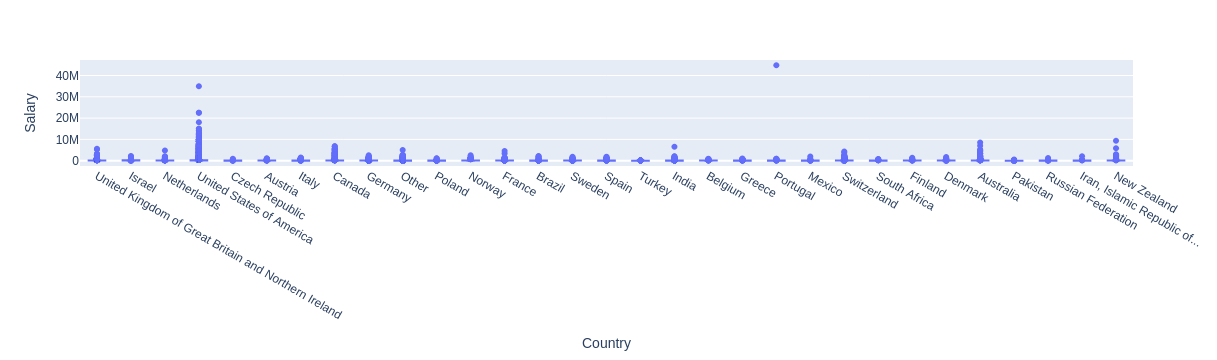

In [30]:
fig = px.box(df, x="Country", y="Salary")
fig.show()

In [31]:
df = df[df["Salary"] <= 300000]
df = df[df["Salary"] >= 10000]
df = df[df['Country'] != 'Other']

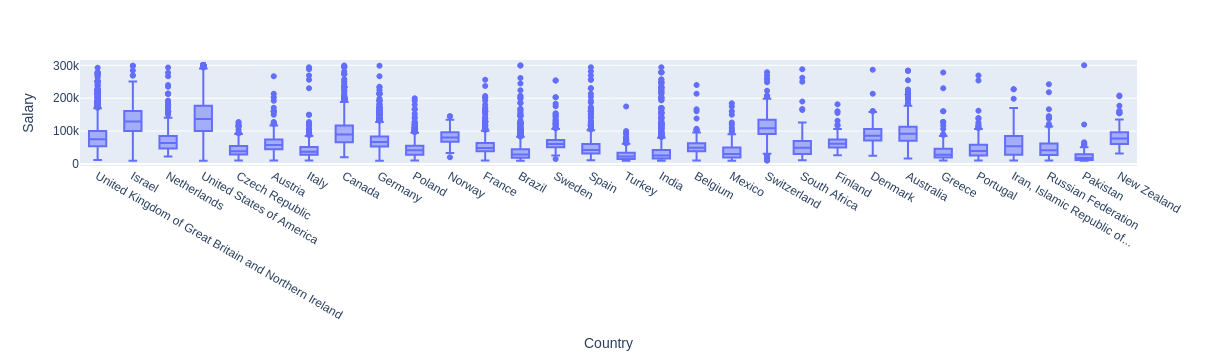

In [32]:
fig = px.box(df, x="Country", y="Salary")
fig.show()

In [33]:
df["YearsCodePro"].unique()

array(['5', '17', '6', '2', '4', '10', '22', '20', '9', '14', '21', '15',
       '3', '25', '7', '8', '12', '19', '24', '1', '11', '23',
       'Less than 1 year', '18', '37', '46', '13', '32', '27', '28', '16',
       '31', '30', '34', '35', '26', '42', '38', '36', '40', '41', '29',
       '33', '39', '48', '45', '44', '43', 'More than 50 years', '47',
       '49', '50'], dtype=object)

In [34]:
def clean_experience(x):
    if x ==  'More than 50 years':
        return 50
    if x == 'Less than 1 year':
        return 0.5
    return float(x)

df['YearsCodePro'] = df['YearsCodePro'].apply(clean_experience)

In [35]:
df["EdLevel"].unique()

array(['Master’s degree (M.A., M.S., M.Eng., MBA, etc.)',
       'Bachelor’s degree (B.A., B.S., B.Eng., etc.)',
       'Secondary school (e.g. American high school, German Realschule or Gymnasium, etc.)',
       'Something else', 'Associate degree (A.A., A.S., etc.)',
       'Some college/university study without earning a degree',
       'Professional degree (JD, MD, etc.)',
       'Other doctoral degree (Ph.D., Ed.D., etc.)',
       'Primary/elementary school'], dtype=object)

In [36]:
def clean_education(x):
    if 'Bachelor’s degree' in x:
        return 'Bachelor’s degree'
    if 'Master’s degree' in x:
        return 'Master’s degree'
    if 'Professional degree' in x or 'Other doctoral' in x:
        return 'Post grad'
    return 'Less than a Bachelors'

df['EdLevel'] = df['EdLevel'].apply(clean_education)

In [37]:
df["EdLevel"].unique()

array(['Master’s degree', 'Bachelor’s degree', 'Less than a Bachelors',
       'Post grad'], dtype=object)

In [38]:
df

,Country,EdLevel,YearsCodePro,Salary
2,United Kingdom of Great Britain and Northern I...,Master’s degree,5.0,40205.0
3,Israel,Bachelor’s degree,17.0,215232.0
8,Netherlands,Master’s degree,6.0,49056.0
10,United Kingdom of Great Britain and Northern I...,Bachelor’s degree,2.0,60307.0
12,United States of America,Bachelor’s degree,5.0,65000.0
...,...,...,...,...
73113,United States of America,Master’s degree,5.0,94000.0
73116,United States of America,Bachelor’s degree,16.0,115000.0
73119,United States of America,Bachelor’s degree,1.0,70000.0
73120,Spain,Bachelor’s degree,2.0,35192.0


## Model Training

Prepare the input features and target, then build a preprocessing pipeline for numerical and categorical columns. The pipeline keeps preprocessing fitted on the training data only.

In [39]:
# Input features and target
X = df.drop("Salary", axis=1)
y = df["Salary"]

# Columns to preprocess
numeric_features = ["YearsCodePro"]
categorical_features = ["Country", "EdLevel"]

numeric_pipeline = Pipeline([
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

transformer = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.10, random_state=1234
)

X_train.head()

,Country,EdLevel,YearsCodePro
3626,Canada,Bachelor’s degree,4.0
9476,Germany,Bachelor’s degree,3.0
71367,Canada,Post grad,12.0
6328,Germany,Bachelor’s degree,2.0
55505,India,Bachelor’s degree,9.0


### Linear Regression

In [40]:
mlpipe1 = Pipeline([
    ("transformer", transformer),
    ("lr", LinearRegression())
])

mlpipe1.fit(X_train, y_train)

y_hat = mlpipe1.predict(X_test)
rmse = np.sqrt(mean_squared_error(y_test, y_hat))
print(f"RMSE: ${rmse:,.2f}")

RMSE: $39,670.28


### Decision Tree Regressor

In [41]:
mlpipe2 = Pipeline([
    ("transformer", transformer),
    ("dt", DecisionTreeRegressor(random_state=1234))
])

mlpipe2.fit(X_train, y_train)

y_hat = mlpipe2.predict(X_test)
rmse = np.sqrt(mean_squared_error(y_test, y_hat))
print(f"RMSE: ${rmse:,.2f}")

RMSE: $40,026.66


### Random Forest Regressor

In [42]:
mlpipe3 = Pipeline([
    ("transformer", transformer),
    ("rf", RandomForestRegressor(random_state=1234))
])

mlpipe3.fit(X_train, y_train)

y_hat = mlpipe3.predict(X_test)
rmse = np.sqrt(mean_squared_error(y_test, y_hat))
print(f"RMSE: ${rmse:,.2f}")

RMSE: $39,471.67


### XGBoost Regressor

In [43]:
mlpipe4 = Pipeline([
    ("transformer", transformer),
    ("xgb", XGBRegressor(
        objective="reg:squarederror",
        random_state=1234
    ))
])

mlpipe4.fit(X_train, y_train)

y_hat = mlpipe4.predict(X_test)
rmse = np.sqrt(mean_squared_error(y_test, y_hat))
print(f"RMSE: ${rmse:,.2f}")

RMSE: $38,987.38


## Compare Model Performance

In [44]:
models = {
    "Linear Regression": mlpipe1,
    "Decision Tree": mlpipe2,
    "Random Forest": mlpipe3,
    "XGBoost": mlpipe4,
}

results = []
for name, model in models.items():
    predictions = model.predict(X_test)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    results.append({"Model": name, "RMSE": rmse})

results_df = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
results_df

,Model,RMSE
0,XGBoost,38987.383436
1,Random Forest,39471.670355
2,Linear Regression,39670.279925
3,Decision Tree,40026.655127


## Predict a Salary for a New Example

Use the same feature names and data types as the training data. The example country and education level must match the categories used by the notebook; unseen categories are handled by the encoder.

In [45]:
X_new = pd.DataFrame([{
    "Country": "Iran, Islamic Republic of...",
    "EdLevel": "Master’s degree",
    "YearsCodePro": 10.0,
}])

prediction = mlpipe4.predict(X_new)
print(f"Predicted yearly salary: ${prediction[0]:,.2f}")

Predicted yearly salary: $78,493.61


## Save and Load the Trained Model

In [46]:
# Save the fitted XGBoost pipeline, including its preprocessing steps.
joblib.dump(mlpipe4, "xgbpipe.joblib")

['xgbpipe.joblib']

In [47]:
# Load the saved pipeline and use it for predictions.
model = joblib.load("xgbpipe.joblib")
yhat = model.predict(X_test)
yhat[:10]

array([ 35211.453,  62887.336,  29985.65 ,  21885.88 ,  86339.984,
       161755.1  ,  65722.25 ,  73253.9  ,  61183.15 , 168480.16 ],
      dtype=float32)